# URB-02 · Grafos urbanos · Versión complementaria (auditoría, noviembre 2026)

> **Copia complementaria** de `URB02_prueba_piloto.ipynb`. **El notebook original no se modifica.**

**Objetivo de esta copia:** definir una intersección piloto de la Vía Perimetral, presentar el modelo nodo–arista–atributos, construir y visualizar un grafo pequeño y calcular dos métricas de conectividad justificadas.

| Parte | Contenido | ¿Se ejecuta para la entrega? |
|---|---|---|
| **Parte C** (a continuación) | Bloque nuevo y autocontenido que cubre los ajustes de la auditoría | **Sí.** Ejecutar desde la celda C.0 hasta el final de la Parte C |
| **Parte B** | Copia del notebook original con ajustes puntuales marcados `# [AJUSTE AUDITORÍA]` | No es necesaria (referencia) |

**Cómo ejecutar:** ver `README_COMPLEMENTARIO.md` en la carpeta del proyecto. En Colab, poner `CLONAR_REPO = True` en la celda C.0 para que los datos de prueba y `COMUN/` se descarguen del repositorio.
Las salidas se guardan en `salidas_complementarias/`.

**Datos:** cada tabla indica `tipo_dato` (`real` / `derivado_real` / `sintetico` / `pendiente`). Los resultados sintéticos **no** deben presentarse como validación real.


# Parte C · Bloque complementario URB-02 (entrega mínima de la auditoría)

**Qué resuelve esta parte:**

1. Define una **intersección piloto de la Vía Perimetral**: el intercambiador de la zona común `PER-Z04`.
2. Presenta explícitamente el **modelo nodo–arista–atributos** con un diagrama y con tablas de nodos y aristas.
3. Construye un **grafo pequeño** de intersecciones y tramos, lo **visualiza** y calcula **dos métricas de conectividad justificadas**.

**Red:** se usa la geometría OSM de la Perimetral incluida en el repositorio (`SIS-API-01/test_Data/geoJsonPerimetral.geojson`), así que la parte corre sin descargas.
Esa capa contiene la Perimetral, sus ramales y sus retornos, **pero no las calles transversales**. La red completa del entorno se descarga con OSMnx en la Parte B (Colab), cuya celda de parámetros ya apunta a esta intersección.

Dependencias: `numpy`, `pandas`, `matplotlib`, `networkx`.

In [1]:
# ===================== C.0 · Base común (idéntica en todos los notebooks complementarios) =====================
# Fuente de verdad: GEMELO DIGITAL/COMUN (contrato_hev_v1.json, zonas_perimetral.*). Si el repositorio no está
# disponible (p. ej. Colab sin clonar), se usa la tabla de zonas embebida más abajo, que es una copia exacta.
import json, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

SEMILLA = 42
rng_c = np.random.default_rng(SEMILLA)

CLONAR_REPO = False          # True en Google Colab para descargar COMUN/ y los datos de prueba del repositorio
URL_REPO = "https://github.com/AaronTech24/Gemelos_Digitales.git"

def buscar_raiz_repo():
    """Devuelve la carpeta 'GEMELO DIGITAL' del repositorio, o None si no se encuentra."""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "COMUN" / "contrato_hev_v1.json").exists():
            return q
        if (q / "GEMELO DIGITAL" / "COMUN" / "contrato_hev_v1.json").exists():
            return q / "GEMELO DIGITAL"
    for q in [Path("/content/Gemelos_Digitales/GEMELO DIGITAL")]:
        if (q / "COMUN").exists():
            return q
    return None

RAIZ = buscar_raiz_repo()
if RAIZ is None and CLONAR_REPO:
    subprocess.run(["git", "clone", "--depth", "1", URL_REPO, "/content/Gemelos_Digitales"], check=False)
    RAIZ = buscar_raiz_repo()

def ruta_dato(*partes):
    """Ruta a un archivo del repositorio (relativa a 'GEMELO DIGITAL') o None si no existe."""
    if RAIZ is None:
        return None
    r = RAIZ.joinpath(*partes)
    return r if r.exists() else None

# --- Zonas comunes de la Vía Perimetral (COMUN/zonas_perimetral.csv, regla v1) ---
LAT_NORTE, LAT_SUR, N_ZONAS = -2.0730, -2.2425, 12
BUFFER_CORREDOR_M = 200
_COLS_Z = ["id_zona", "lat_max", "lat_min", "centroide_lat", "centroide_lon", "area_km2",
           "longitud_eje_km", "vel_max_osm_kmh", "carriles_osm"]
ZONAS_EMBEBIDAS = [
    ('PER-Z01', -2.073, -2.087125, -2.080262, -79.93277, 1.491, 3.88, 90, 3),
    ('PER-Z02', -2.087125, -2.10125, -2.094077, -79.947805, 0.662, 1.59, 90, 3),
    ('PER-Z03', -2.10125, -2.115375, -2.108339, -79.947903, 0.68, 2.29, 90, 3),
    ('PER-Z04', -2.115375, -2.1295, -2.122392, -79.948995, 0.713, 3.22, 60, 3),
    ('PER-Z05', -2.1295, -2.143625, -2.136494, -79.94695, 0.674, 1.62, 90, 3),
    ('PER-Z06', -2.143625, -2.15775, -2.15081, -79.94666, 0.675, 1.61, 90, 3),
    ('PER-Z07', -2.15775, -2.171875, -2.164975, -79.947666, 0.688, 1.65, 90, 3),
    ('PER-Z08', -2.171875, -2.186, -2.179743, -79.947688, 0.798, 1.92, 90, 3),
    ('PER-Z09', -2.186, -2.200125, -2.192248, -79.957006, 0.789, 1.87, 90, 3),
    ('PER-Z10', -2.200125, -2.21425, -2.207136, -79.956081, 0.664, 1.59, 90, 3),
    ('PER-Z11', -2.21425, -2.228375, -2.221591, -79.956534, 0.691, 1.65, 90, 3),
    ('PER-Z12', -2.228375, -2.2425, -2.235703, -79.933396, 2.147, 7.73, 90, 3)
]

def cargar_zonas():
    r = ruta_dato("COMUN", "zonas_perimetral.csv")
    if r is not None:
        z = pd.read_csv(r)
        z["origen_tabla"] = "COMUN/zonas_perimetral.csv"
    else:
        z = pd.DataFrame(ZONAS_EMBEBIDAS, columns=_COLS_Z)
        z["origen_tabla"] = "tabla embebida (copia de COMUN v1)"
    return z

ZONAS = cargar_zonas()
IDS_ZONA = ZONAS["id_zona"].tolist()

def asignar_zona(lat):
    """Regla común: franja de latitud (norte -> sur). Devuelve NaN fuera del rango del corredor."""
    lat = pd.Series(np.atleast_1d(lat), dtype=float)
    k = np.floor((LAT_NORTE - lat) / ((LAT_NORTE - LAT_SUR) / N_ZONAS))
    k = k.where((k >= 0) & (k < N_ZONAS))
    return k.map(lambda i: f"PER-Z{int(i) + 1:02d}" if pd.notna(i) else None).values

CORTES_NIVEL = [0.25, 0.50, 0.75]
def nivel(x):
    return pd.cut(pd.Series(x, dtype=float), [-np.inf, *CORTES_NIVEL, np.inf], right=False,
                  labels=["bajo", "medio", "alto", "critico"]).astype(str).values

# --- Cargador común de eventos reales (siniestros ATM y homicidios), con deduplicación documentada ---
_VEHICULOS = ["AUTOMOVIL", "BICICLETA", "BUS", "CAMION", "CAMIONETA", "EMERGENCIAS", "ESPECIAL", "FURGONETA",
              "MOTOCICLETA", "NO_IDENTIFICADO", "SCOOTER_ELECTRICO", "TRICIMOTO", "VEHICULO_DEPORTIVO_UTILITARIO"]

def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False), errors="coerce")

def cargar_eventos_reales():
    """Devuelve (EVENTOS, CALIDAD) en el esquema 'evento' del contrato. No inventa nada si faltan archivos.

    Regla de deduplicación ATM: la unidad es el código SINIESTROS. En el CSV filtrado, 1 080 filas son duplicados
    exactos y otras repiten el código cambiando solo columnas de vehículos; se conserva 1 fila por código y los
    vehículos se combinan con el máximo (presencia del tipo de vehículo en el siniestro).
    """
    eventos, calidad = [], []
    r_acc = ruta_dato("URB-04", "test_Data", "siniestros_via_perimetral_guayaquil.csv")
    r_hom = ruta_dato("URB-04", "test_Data", "homicidios_via_perimetral.csv")
    if r_acc is not None:
        a = pd.read_csv(r_acc, sep=";", encoding="utf-8-sig", dtype=str)
        n0 = len(a)
        dup_exactos = int(a.drop(columns=["id"]).duplicated().sum())
        for c in _VEHICULOS:
            a[c] = _num(a[c]).fillna(0)
        veh = a.groupby("SINIESTROS")[_VEHICULOS].max()
        a = a.drop_duplicates("SINIESTROS").set_index("SINIESTROS").drop(columns=_VEHICULOS).join(veh).reset_index()
        les, fal = _num(a.LESIONADOS).fillna(0).astype(int), _num(a.FALLECIDOS).fillna(0).astype(int)
        ev = pd.DataFrame({
            "id_evento": a.SINIESTROS, "riesgo": "accidentes_viales",
            "fecha_hora": pd.to_datetime(a.FECHA + " " + a.HORA, format="%d/%m/%Y %H:%M:%S", errors="coerce"),
            "lat": _num(a.LATITUD_Y), "lon": _num(a.LONGITUD_X), "subtipo": a.TIPO_DE_SINIESTRO,
            # severidad 1-4 (contrato): 4 con fallecidos · 3 con >= 3 lesionados · 2 con lesionados · 1 sin víctimas
            "severidad": np.select([fal > 0, les >= 3, les > 0], [4, 3, 2], 1),
            "lesionados": les, "fallecidos": fal, "motocicleta": a.MOTOCICLETA > 0,
            "arma_fuego": np.nan, "causa": a.CAUSA_PROBABLE, "feriado": a.FERIADO.eq("SI"),
            "via_osm_id": a.via_osm_id, "fuente": "F01 ATM", "tipo_dato": "real"})
        calidad.append({"riesgo": "accidentes_viales", "filas_csv": n0, "duplicados_exactos": dup_exactos,
                        "filas_extra_mismo_codigo": n0 - dup_exactos - len(ev), "eventos_unicos": len(ev)})
        eventos.append(ev)
    if r_hom is not None:
        h = pd.read_csv(r_hom, encoding="utf-8-sig", dtype=str)
        ev = pd.DataFrame({
            "id_evento": "HOM-" + h["id"].str.zfill(4), "riesgo": "seguridad_urbana",
            "fecha_hora": pd.to_datetime(h.fecha.str[:10] + " " + h.hora_infraccion.fillna("00:00:00"), errors="coerce"),
            "lat": _num(h.coordenada_y), "lon": _num(h.coordenada_x), "subtipo": h.tipo_muerte,
            "severidad": 4, "lesionados": 0, "fallecidos": 1, "motocicleta": np.nan,
            "arma_fuego": h.arma.str.contains("fuego", case=False, na=False), "causa": h.presunta_motivacion,
            "feriado": np.nan, "via_osm_id": h.via_osm_id, "fuente": "F02 homicidios", "tipo_dato": "real"})
        calidad.append({"riesgo": "seguridad_urbana", "filas_csv": len(h),
                        "duplicados_exactos": int(h.drop(columns=["id"]).duplicated().sum()),
                        "filas_extra_mismo_codigo": 0, "eventos_unicos": len(ev)})
        eventos.append(ev)
    if not eventos:
        return pd.DataFrame(columns=["id_evento", "riesgo", "fecha_hora", "lat", "lon", "id_zona"]), pd.DataFrame()
    E = pd.concat(eventos, ignore_index=True)
    E["id_zona"] = asignar_zona(E["lat"])
    C = pd.DataFrame(calidad).set_index("riesgo")
    C["fecha_invalida"] = E.groupby("riesgo").fecha_hora.apply(lambda s: int(s.isna().sum()))
    C["coordenada_invalida"] = E.groupby("riesgo").apply(lambda g: int(g[["lat", "lon"]].isna().any(axis=1).sum()))
    C["fuera_del_corredor"] = E.groupby("riesgo").id_zona.apply(lambda s: int(s.isna().sum()))
    C["desde"] = E.groupby("riesgo").fecha_hora.min()
    C["hasta"] = E.groupby("riesgo").fecha_hora.max()
    # Homicidios antes de 2023: <= 10 por año en la base -> cobertura incompleta; se excluyen de los indicadores.
    E["usar_en_indicadores"] = ~((E.riesgo == "seguridad_urbana") & (E.fecha_hora.dt.year < 2023))
    return E.dropna(subset=["id_zona"]).reset_index(drop=True), C.reset_index()

SALIDA_C = Path("salidas_complementarias")
SALIDA_C.mkdir(exist_ok=True)

print("Repositorio encontrado:", RAIZ if RAIZ else "NO (se usan tablas embebidas / datos sintéticos)")
print("Zonas comunes:", len(ZONAS), "|", ZONAS["origen_tabla"].iloc[0], "| salidas ->", SALIDA_C.resolve())

Repositorio encontrado: /home/claude/gemelos_digitales/GEMELO DIGITAL
Zonas comunes: 12 | COMUN/zonas_perimetral.csv | salidas -> /home/claude/gemelos_digitales/GEMELO DIGITAL/URB-02/src/salidas_complementarias


## C.1 · Modelo nodo–arista–atributos

| Elemento | Qué representa en la Perimetral | Identificador | Atributos |
|---|---|---|---|
| **Nodo** | Intersección: empalme de ramal o retorno (grado ≥ 3), o extremo del recorte de la zona (grado 1) | `N###` (+ `lon`, `lat`) | `grado`, `id_zona`, `tipo_nodo` |
| **Arista** | Tramo de calzada entre dos nodos consecutivos (une una o varias vías OSM) | `S####` + `ways` (`way/<osm_id>`) | `longitud_m`, `highway`, `carriles`, `vel_max_kmh`, `oneway`, `puente`, `siniestros` (ATM) |
| **Atributo de red** | Métrica calculada sobre la topología | — | `intermediacion` (aristas y nodos), `perdida_eficiencia` (nodos) |

El grafo se trata como **no dirigido y ponderado por longitud**: mide conectividad estructural. El sentido de circulación (`oneway`) se conserva como atributo de la arista.

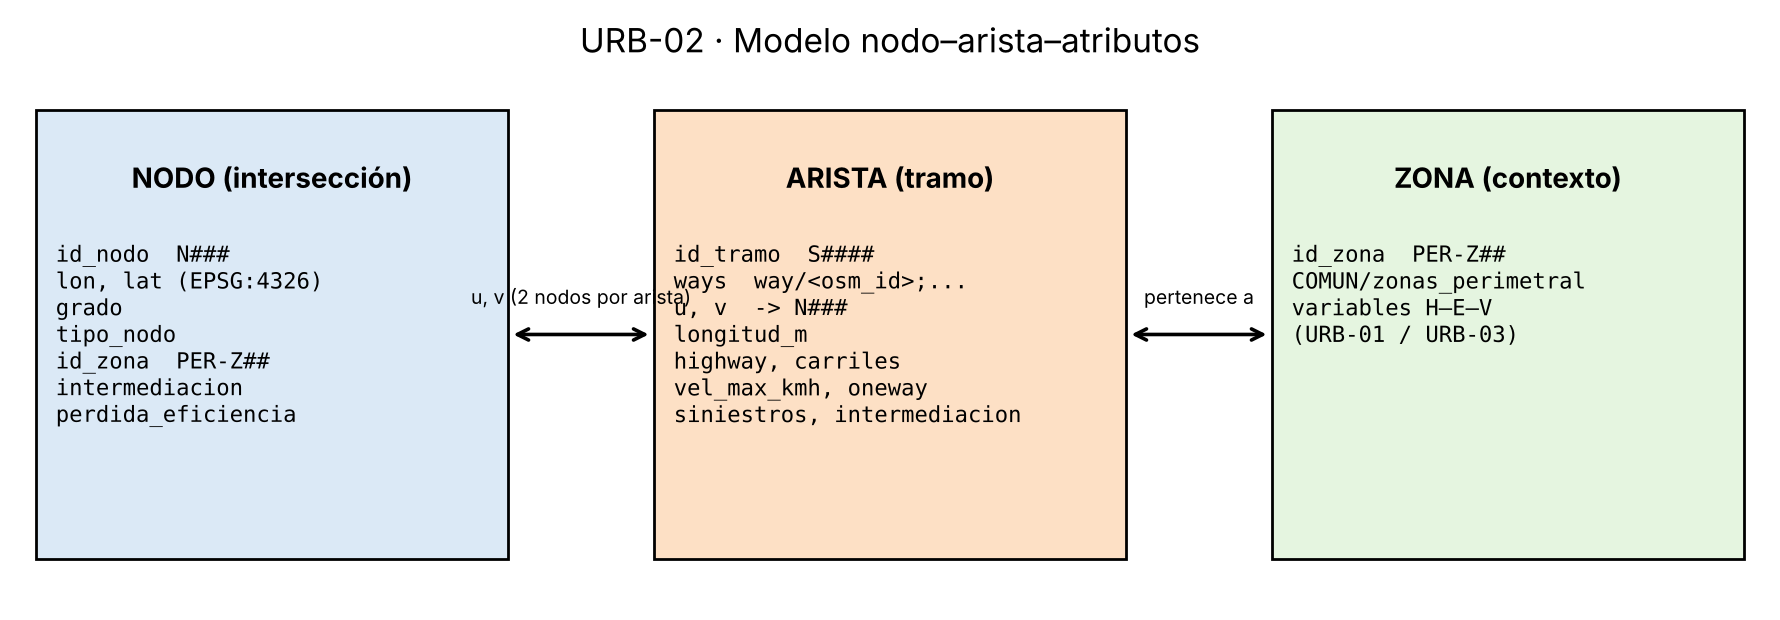

In [2]:
import math
from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx

# Diagrama del modelo (figura para la presentación)
fig, ax = plt.subplots(figsize=(9, 3.2)); ax.axis("off")
def caja(x, y, titulo, lineas, color):
    ax.add_patch(plt.Rectangle((x, y), 2.9, 2.2, fc=color, ec="k", lw=1))
    ax.text(x + 1.45, y + 1.95, titulo, ha="center", va="top", weight="bold", fontsize=10)
    ax.text(x + 0.12, y + 1.55, "\n".join(lineas), va="top", fontsize=8, family="monospace")
caja(0.0, 0.2, "NODO (intersección)", ["id_nodo  N###", "lon, lat (EPSG:4326)", "grado", "tipo_nodo", "id_zona  PER-Z##",
                                       "intermediacion", "perdida_eficiencia"], "#dbe9f6")
caja(3.8, 0.2, "ARISTA (tramo)", ["id_tramo  S####", "ways  way/<osm_id>;...", "u, v  -> N###", "longitud_m", "highway, carriles",
                                   "vel_max_kmh, oneway", "siniestros, intermediacion"], "#fde0c5")
caja(7.6, 0.2, "ZONA (contexto)", ["id_zona  PER-Z##", "COMUN/zonas_perimetral", "variables H–E–V", "(URB-01 / URB-03)"], "#e5f5e0")
for x0, x1, t in [(2.9, 3.8, "u, v (2 nodos por arista)"), (6.7, 7.6, "pertenece a")]:
    ax.annotate("", xy=(x1, 1.3), xytext=(x0, 1.3), arrowprops=dict(arrowstyle="<->", lw=1.3))
    ax.text((x0 + x1) / 2, 1.45, t, ha="center", fontsize=7)
ax.set_xlim(-0.1, 10.6); ax.set_ylim(0, 2.6)
ax.set_title("URB-02 · Modelo nodo–arista–atributos")
plt.tight_layout(); plt.savefig(SALIDA_C / "urb02_diagrama_modelo_grafo.png", dpi=140); plt.show()

## C.2 · Construcción del grafo de la Perimetral y elección de la intersección piloto

In [3]:
r_red = ruta_dato("SIS-API-01", "test_Data", "geoJsonPerimetral.geojson")
assert r_red is not None, "Se necesita geoJsonPerimetral.geojson (clonar el repositorio: CLONAR_REPO=True en C.0)"
RED = json.loads(r_red.read_text(encoding="utf-8"))

def k6(c):
    return (round(c[0], 6), round(c[1], 6))

def dist_m(a, b):
    R = 6_371_000
    la1, la2 = math.radians(a[1]), math.radians(b[1])
    return 2 * R * math.asin(math.sqrt(math.sin((la2 - la1) / 2) ** 2 +
                                       math.cos(la1) * math.cos(la2) * math.sin(math.radians(b[0] - a[0]) / 2) ** 2))

# Nodos = vértices compartidos por >= 2 vías + extremos de cada vía
usos, extremos = Counter(), set()
for f in RED["features"]:
    cs = [k6(c) for c in f["geometry"]["coordinates"]]
    usos.update(set(cs)); extremos.update([cs[0], cs[-1]])
CORTES = {c for c, n in usos.items() if n > 1} | extremos

G_total = nx.MultiGraph()
for f in RED["features"]:
    p = f["properties"]
    cs = [k6(c) for c in f["geometry"]["coordinates"]]
    ini, L, geom = 0, 0.0, [cs[0]]
    for i in range(1, len(cs)):
        L += dist_m(cs[i - 1], cs[i]); geom.append(cs[i])
        if cs[i] in CORTES:
            G_total.add_edge(cs[ini], cs[i], way=p["@id"], longitud_m=round(L, 1), highway=p.get("highway"),
                             carriles=int(p["lanes"]) if p.get("lanes") else None,
                             vel_max_kmh=int(p["maxspeed"]) if p.get("maxspeed") else None,
                             oneway=p.get("oneway") == "yes", puente=p.get("bridge") == "yes", geom=geom)
            ini, L, geom = i, 0.0, [cs[i]]

nodos_tot = pd.DataFrame([{"lon": n[0], "lat": n[1], "grado": d} for n, d in G_total.degree()])
nodos_tot["id_zona"] = asignar_zona(nodos_tot.lat)
print(f"Grafo completo de la Perimetral: {G_total.number_of_nodes()} nodos, {G_total.number_of_edges()} aristas, "
      f"{nx.number_connected_components(nx.Graph(G_total))} componentes (una por calzada)")

EVENTOS, _ = cargar_eventos_reales()
acc = EVENTOS[EVENTOS.riesgo == "accidentes_viales"]
cand = (nodos_tot.assign(interseccion=nodos_tot.grado >= 3).groupby("id_zona")
        .agg(nodos=("grado", "size"), intersecciones=("interseccion", "sum")))
cand["siniestros_ATM"] = acc.groupby("id_zona").size()
cand["pct_atropellos"] = (100 * acc.groupby("id_zona").subtipo.apply(lambda s: (s == "ATROPELLOS").mean())).round(1)
cand = cand.join(ZONAS.set_index("id_zona")[["longitud_eje_km", "vel_max_osm_kmh"]]).fillna(0)
display(cand)

Grafo completo de la Perimetral: 155 nodos, 159 aristas, 2 componentes (una por calzada)


,nodos,intersecciones,siniestros_ATM,pct_atropellos,longitud_eje_km,vel_max_osm_kmh
id_zona,,,,,,
PER-Z01,25,2,74,16.2,3.88,90
PER-Z02,2,0,25,20.0,1.59,90
PER-Z03,14,2,41,14.6,2.29,90
PER-Z04,23,5,65,30.8,3.22,60
PER-Z05,5,1,59,10.2,1.62,90
PER-Z06,9,0,22,9.1,1.61,90
PER-Z07,1,0,9,0.0,1.65,90
PER-Z08,6,0,30,6.7,1.92,90
PER-Z09,17,0,37,10.8,1.87,90


**Criterio de elección.** Se busca una zona que reúna tres condiciones: tener un intercambiador real (varios nodos de grado ≥ 3), no ser uno de los extremos donde la franja agrupa demasiada vía (Z01 y Z12), y tener siniestralidad relevante.
`PER-Z04` es la zona intermedia con más intersecciones. Además tiene la mayor proporción de atropellos del corredor y es el único tramo con límite de 60 km/h, lo que indica un entorno urbano con peatones.
Para cambiar la intersección piloto basta con editar `ZONA_PILOTO`.

In [4]:
ZONA_PILOTO = "PER-Z04"
zp = ZONAS.set_index("id_zona").loc[ZONA_PILOTO]
lat_min, lat_max = zp.lat_min, zp.lat_max

# Subgrafo piloto: aristas con algún extremo dentro de la franja de la zona
G0 = nx.MultiGraph()
for u, v, d in G_total.edges(data=True):
    if lat_min < u[1] <= lat_max or lat_min < v[1] <= lat_max:
        G0.add_edge(u, v, partes=[{c: d[c] for c in ["way", "longitud_m", "highway", "carriles", "vel_max_kmh", "oneway", "puente"]}],
                    longitud_m=d["longitud_m"], geom=d["geom"])

def simplificar(G):
    """Fusiona los nodos de grado 2 (cortes entre vías OSM sin intersección real), como hace OSMnx con simplify=True.
    Quedan como nodos solo las intersecciones (grado >= 3) y los extremos del recorte (grado 1)."""
    G = G.copy()
    cambiado = True
    while cambiado:
        cambiado = False
        for n in list(G.nodes):
            ed = list(G.edges(n, keys=True, data=True))
            if G.degree(n) != 2 or len(ed) != 2 or any(b == n for _, b, _, _ in ed):
                continue
            (_, b1, _, d1), (_, b2, _, d2) = ed
            g1 = d1["geom"] if d1["geom"][-1] == n else d1["geom"][::-1]
            g2 = d2["geom"] if d2["geom"][0] == n else d2["geom"][::-1]
            G.remove_node(n)
            G.add_edge(b1, b2, partes=d1["partes"] + d2["partes"], longitud_m=round(d1["longitud_m"] + d2["longitud_m"], 1),
                       geom=g1 + g2[1:])
            cambiado = True
    return G

G = simplificar(G0)
print(f"Antes de simplificar: {G0.number_of_nodes()} nodos / {G0.number_of_edges()} aristas · "
      f"después: {G.number_of_nodes()} nodos / {G.number_of_edges()} aristas")

ids_nodo = {n: f"N{i + 1:03d}" for i, n in enumerate(sorted(G.nodes, key=lambda c: (-c[1], c[0])))}
NODOS = pd.DataFrame([{"id_nodo": ids_nodo[n], "lon": n[0], "lat": n[1], "grado": G.degree(n)} for n in G.nodes])
NODOS["id_zona"] = asignar_zona(NODOS.lat)
NODOS["tipo_nodo"] = np.where(NODOS.grado >= 3, "interseccion", "extremo")

filas = []
for i, (u, v, k, d) in enumerate(G.edges(keys=True, data=True)):
    pz = pd.DataFrame(d["partes"])
    larga = pz.loc[pz.longitud_m.idxmax()]                       # atributos del tramo OSM más largo
    filas.append({"id_tramo": f"S{i + 1:04d}", "u": ids_nodo[u], "v": ids_nodo[v], "longitud_m": d["longitud_m"],
                  "ways": ";".join(dict.fromkeys(pz.way)), "highway": larga.highway,
                  "carriles": larga.carriles, "vel_max_kmh": larga.vel_max_kmh,
                  "oneway": bool(pz.oneway.all()), "puente": bool(pz.puente.any())})
    d["id_tramo"] = f"S{i + 1:04d}"
ARISTAS = pd.DataFrame(filas)

# Siniestros ATM reales asociados a cada tramo por su vía OSM más cercana (columna via_osm_id del CSV)
sin_way = acc[acc.id_zona == ZONA_PILOTO].groupby("via_osm_id").size()
ways_tramo = ARISTAS.ways.str.split(";")
tramos_por_way = ways_tramo.explode().value_counts()
ARISTAS["siniestros"] = ways_tramo.apply(lambda ws: sum(sin_way.get(w, 0) / tramos_por_way[w] for w in ws)).round(2)
print(f"Grafo piloto {ZONA_PILOTO}: {len(NODOS)} nodos ({(NODOS.tipo_nodo == 'interseccion').sum()} intersecciones), "
      f"{len(ARISTAS)} tramos, {ARISTAS.longitud_m.sum() / 1000:.2f} km de calzada, "
      f"{int(sin_way.sum())} siniestros ATM asociados")

Antes de simplificar: 28 nodos / 29 aristas · después: 8 nodos / 9 aristas
Grafo piloto PER-Z04: 8 nodos (5 intersecciones), 9 tramos, 6.89 km de calzada, 65 siniestros ATM asociados


## C.3 · Dos métricas de conectividad y su justificación

| Métrica | Definición | Por qué sirve para el riesgo |
|---|---|---|
| **1. Intermediación (betweenness) ponderada por longitud**, en aristas y nodos | Proporción de los caminos más cortos entre todos los pares de nodos que pasan por el elemento (Freeman, 1977) | Señala los tramos por los que **pasa más tráfico potencial**. Un siniestro o un anegamiento ahí afecta a más recorridos: es una medida de **exposición** estructural. |
| **2. Pérdida de eficiencia global al retirar el nodo** | $\Delta E_i = (E(G) - E(G \setminus i)) / E(G)$, con $E = \frac{1}{n(n-1)}\sum_{a \ne b} 1/d_{ab}$ (Latora y Marchiori, 2001). Se mantiene el $n$ original, así que los pares que pierden el nodo cuentan como 0 y $\Delta E_i \in [0, 1]$ | Simula el **cierre** de una intersección (accidente, inundación, operativo) y mide cuánta accesibilidad pierde la red. Es una medida de **vulnerabilidad** de la conectividad. |

Las dos métricas son complementarias. La intermediación indica **por dónde pasa** el flujo; la pérdida de eficiencia indica **qué tan grave es perder** un punto.

In [5]:
Gs = nx.Graph()
for u, v, d in G.edges(data=True):          # grafo simple: entre aristas paralelas se conserva la más corta
    if not Gs.has_edge(u, v) or d["longitud_m"] < Gs[u][v]["longitud_m"]:
        Gs.add_edge(u, v, longitud_m=d["longitud_m"], id_tramo=d["id_tramo"])

bet_n = nx.betweenness_centrality(Gs, weight="longitud_m", normalized=True)
bet_e = nx.edge_betweenness_centrality(Gs, weight="longitud_m", normalized=True)

def eficiencia_global(H, n_ref=None):
    """Eficiencia de Latora-Marchiori. Con n_ref fijo, los pares que pierden el nodo retirado cuentan como 0."""
    n = n_ref or H.number_of_nodes()
    if n < 2:
        return 0.0
    tot = 0.0
    for _, dist in nx.all_pairs_dijkstra_path_length(H, weight="longitud_m"):
        tot += sum(1 / x for x in dist.values() if x > 0)
    return tot / (n * (n - 1))

E0 = eficiencia_global(Gs)
perdida = {}
for n in Gs.nodes:
    H = Gs.copy(); H.remove_node(n)
    perdida[n] = (E0 - eficiencia_global(H, n_ref=Gs.number_of_nodes())) / E0

inv = {v: k for k, v in ids_nodo.items()}
NODOS["intermediacion"] = NODOS.id_nodo.map(lambda i: bet_n[inv[i]]).round(4)
NODOS["perdida_eficiencia"] = NODOS.id_nodo.map(lambda i: perdida[inv[i]]).round(4)
NODOS["punto_articulacion"] = NODOS.id_nodo.map(lambda i: inv[i] in set(nx.articulation_points(Gs)))
tramo_bet = {Gs[u][v]["id_tramo"]: b for (u, v), b in bet_e.items()}
ARISTAS["intermediacion"] = ARISTAS.id_tramo.map(tramo_bet).fillna(0).round(4)   # 0 = arista paralela descartada

print(f"Eficiencia global del grafo piloto: E(G) = {E0:.6f} (1/m)")
print("Nodos más críticos por pérdida de eficiencia:")
display(NODOS.sort_values("perdida_eficiencia", ascending=False).head(8))
print("Tramos con mayor intermediación:")
display(ARISTAS.sort_values("intermediacion", ascending=False).head(8))

Eficiencia global del grafo piloto: E(G) = 0.001202 (1/m)
Nodos más críticos por pérdida de eficiencia:


,id_nodo,lon,lat,grado,id_zona,tipo_nodo,intermediacion,perdida_eficiencia,punto_articulacion
3,N007,-79.948968,-2.129242,3,PER-Z04,interseccion,0.1429,0.5127,True
2,N008,-79.948697,-2.130115,1,PER-Z05,extremo,0.0000,0.3816,False
1,N002,-79.948310,-2.116080,3,PER-Z04,interseccion,0.0952,0.3205,True
5,N003,-79.949365,-2.121915,3,PER-Z04,interseccion,0.0952,0.2637,False
0,N001,-79.948238,-2.114556,1,PER-Z03,extremo,0.0000,0.2400,False
6,N004,-79.949430,-2.123508,3,PER-Z04,interseccion,0.0000,0.2318,False
7,N006,-79.949285,-2.124757,1,PER-Z04,extremo,0.0000,0.1335,False
4,N005,-79.949298,-2.123571,3,PER-Z04,interseccion,0.0000,0.1126,False


Tramos con mayor intermediación:


,id_tramo,u,v,longitud_m,ways,highway,carriles,vel_max_kmh,oneway,puente,siniestros,intermediacion
1,S0002,N002,N003,659.4,way/419269302;way/537431130,secondary,3.0,60.0,True,False,11.00,0.1429
0,S0001,N001,N002,170.2,way/46331088;way/425220053,secondary,NaN,NaN,False,False,0.00,0.1071
3,S0004,N008,N007,101.6,way/186301321,trunk,3.0,90.0,True,False,3.67,0.1071
4,S0005,N007,N005,639.2,way/186301321,trunk,3.0,90.0,True,False,3.67,0.1071
5,S0006,N007,N006,506.5,way/537416191;way/1176316421;way/558940688,residential,2.0,30.0,True,False,2.00,0.1071
7,S0008,N003,N004,178.2,way/537431129,secondary,2.0,NaN,True,False,0.00,0.1071
2,S0003,N002,N004,1135.6,way/431705586;way/1554558331;way/431705588;way...,trunk,3.0,90.0,True,True,9.00,0.0000
6,S0007,N005,N005,1924.7,way/419271677;way/1219679940;way/431706478;way...,secondary,NaN,60.0,True,True,25.67,0.0000


In [6]:
# Relación exploratoria entre intermediación y siniestros (n pequeño: solo descriptiva, no es validación)
from scipy.stats import spearmanr
m = ARISTAS[ARISTAS.intermediacion > 0]
rho, p = spearmanr(m.intermediacion, m.siniestros)
print(f"Spearman intermediación vs. siniestros por tramo: rho = {rho:.2f} (p = {p:.3f}, n = {len(m)} tramos). "
      "Con tan pocos tramos y siniestros asignados por vía OSM, este valor es solo exploratorio.")

Spearman intermediación vs. siniestros por tramo: rho = 0.67 (p = 0.142, n = 6 tramos). Con tan pocos tramos y siniestros asignados por vía OSM, este valor es solo exploratorio.


## C.4 · Visualización del grafo piloto

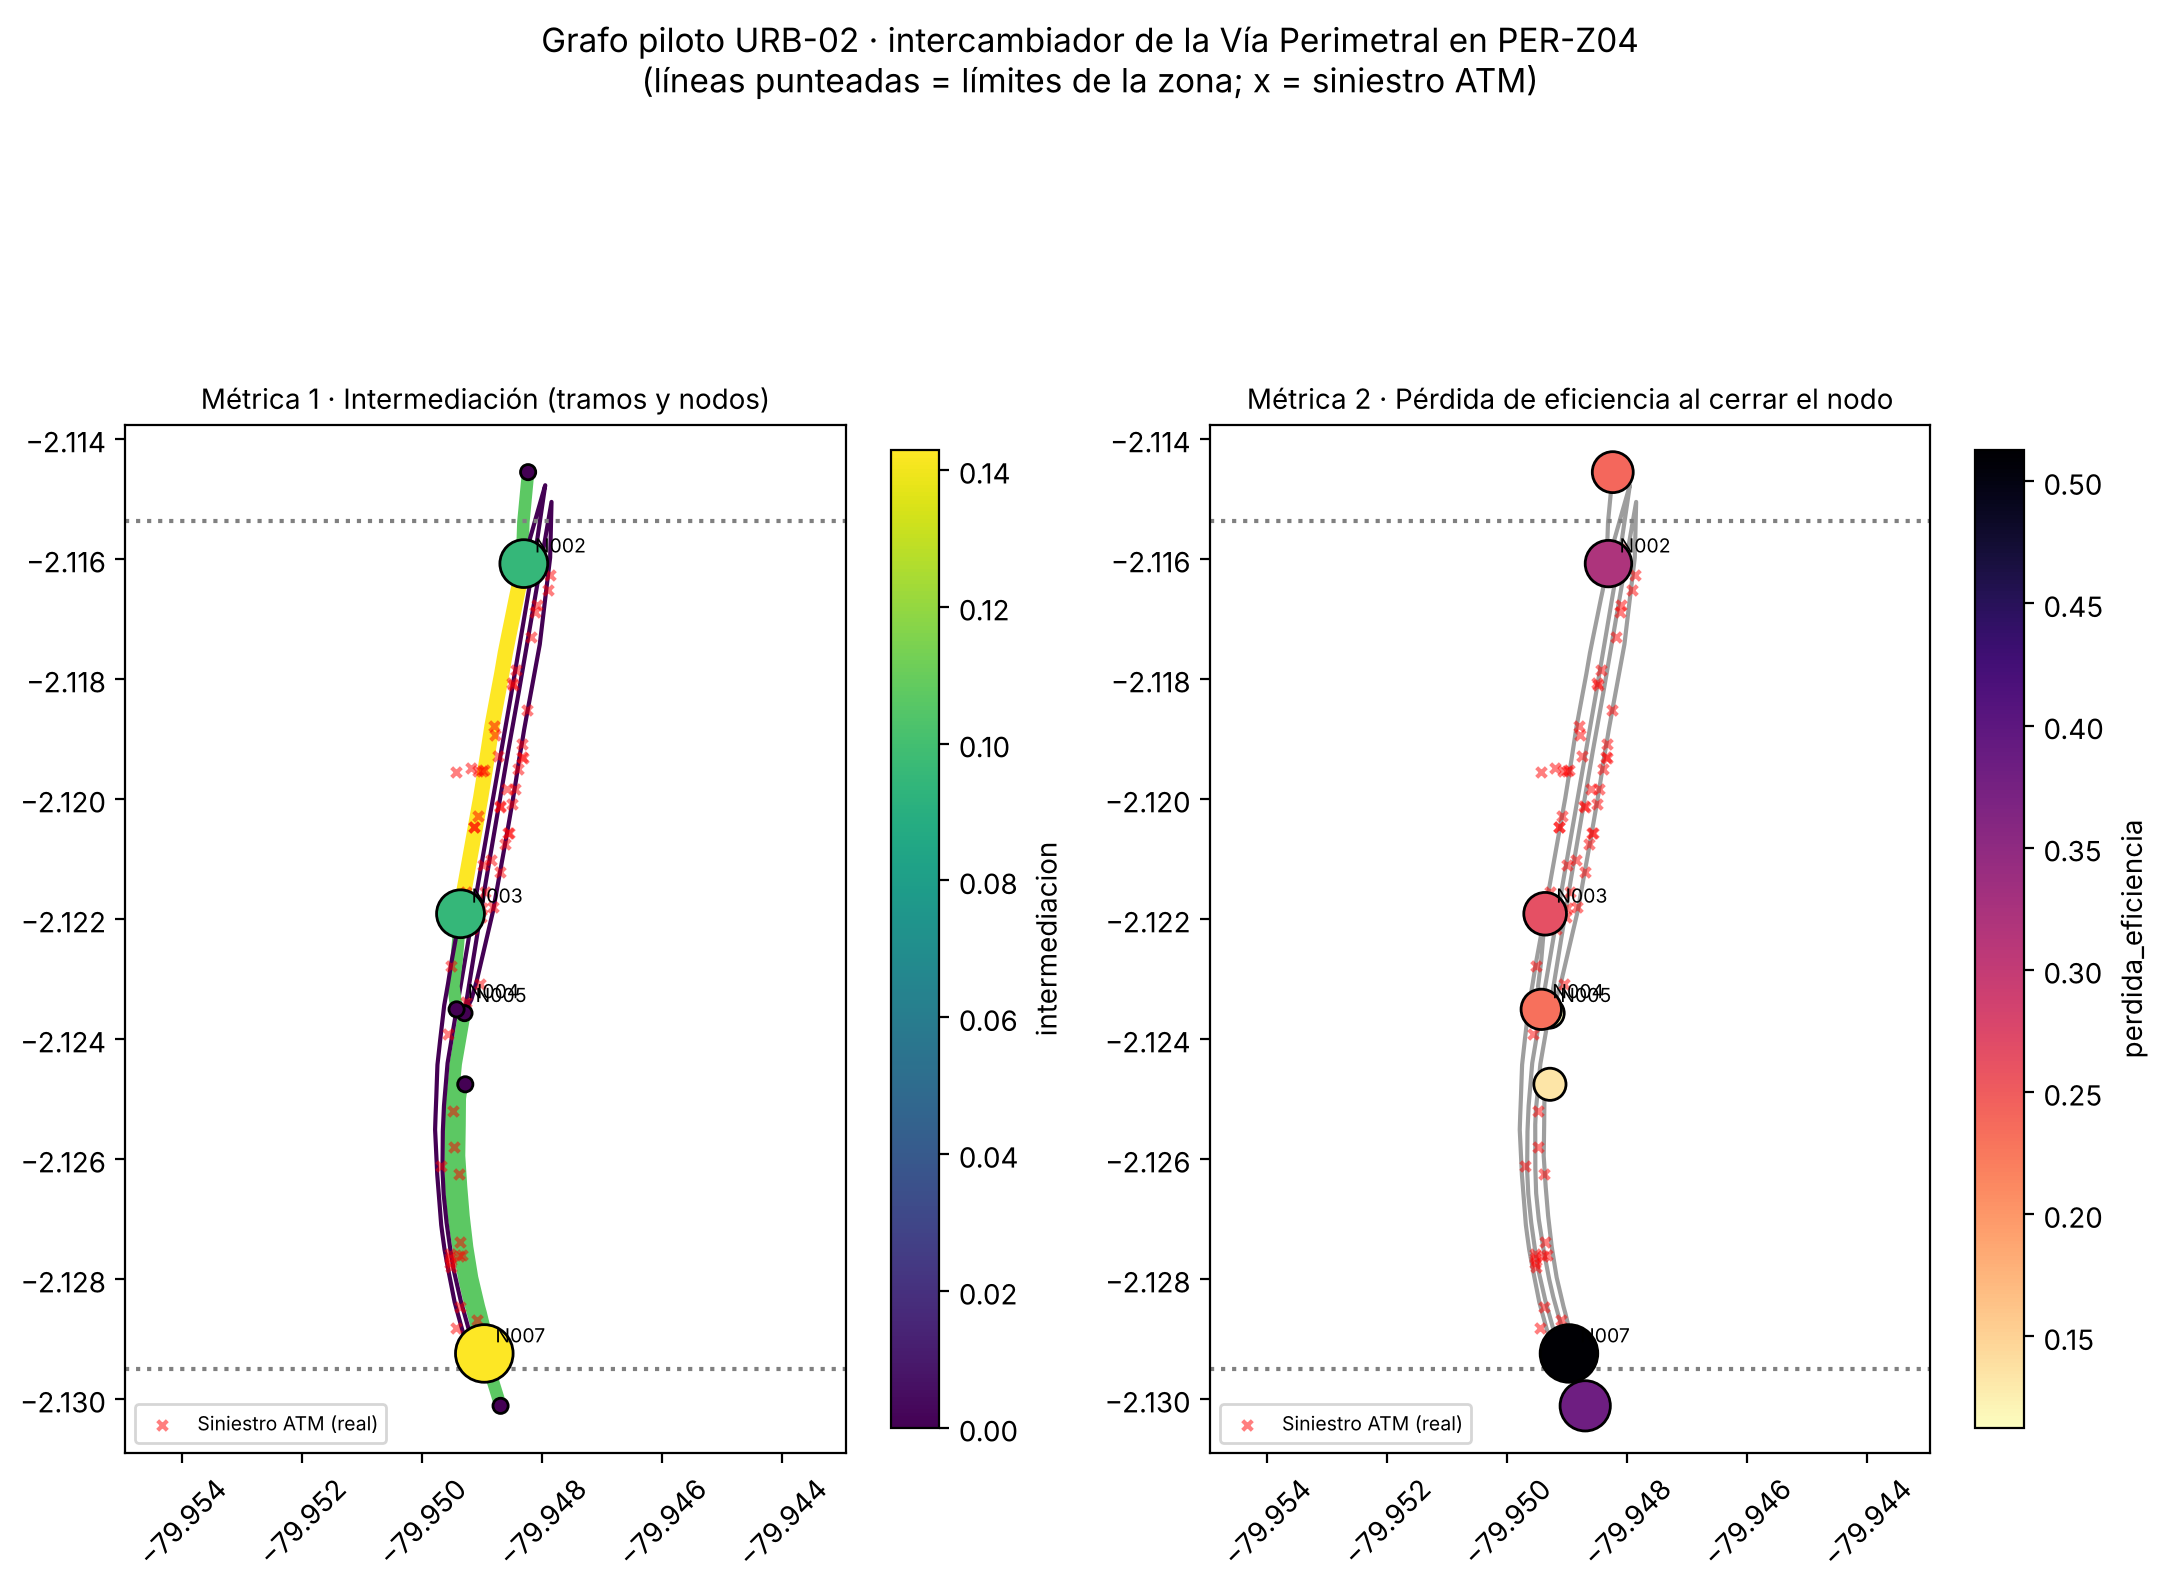

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 9))
for ax, (col, titulo, cmap) in zip(axes, [("intermediacion", "Métrica 1 · Intermediación (tramos y nodos)", "viridis"),
                                          ("perdida_eficiencia", "Métrica 2 · Pérdida de eficiencia al cerrar el nodo", "magma_r")]):
    vals = ARISTAS.set_index("id_tramo").intermediacion
    norm_e = plt.Normalize(0, max(vals.max(), 1e-9))
    for u, v, d in G.edges(data=True):
        xy = np.array(d["geom"])
        ax.plot(xy[:, 0], xy[:, 1], color=plt.get_cmap("viridis")(norm_e(vals[d["id_tramo"]])) if col == "intermediacion" else "#9e9e9e",
                lw=1.5 + 4 * norm_e(vals[d["id_tramo"]]) if col == "intermediacion" else 1.5, zorder=1)
    sc = ax.scatter(NODOS.lon, NODOS.lat, c=NODOS[col], cmap=cmap, s=30 + 400 * NODOS[col] / max(NODOS[col].max(), 1e-9),
                    edgecolor="k", zorder=3)
    for r in NODOS[NODOS.tipo_nodo == "interseccion"].itertuples():
        ax.annotate(r.id_nodo, (r.lon, r.lat), xytext=(4, 4), textcoords="offset points", fontsize=7)
    acc_p = acc[acc.id_zona == ZONA_PILOTO]
    ax.scatter(acc_p.lon, acc_p.lat, marker="x", s=12, color="red", alpha=0.5, label="Siniestro ATM (real)", zorder=2)
    ax.axhline(lat_min, ls=":", c="grey"); ax.axhline(lat_max, ls=":", c="grey")
    plt.colorbar(sc, ax=ax, shrink=0.6, label=col)
    ax.set_title(titulo, fontsize=10); ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=7)
    cx = NODOS.lon.mean(); ax.set_xlim(cx - 0.006, cx + 0.006)
    ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", labelrotation=45)
fig.suptitle(f"Grafo piloto URB-02 · intercambiador de la Vía Perimetral en {ZONA_PILOTO}\n(líneas punteadas = límites de la zona; x = siniestro ATM)")
plt.tight_layout(); plt.savefig(SALIDA_C / "urb02_mapa_grafo_piloto.png", dpi=140); plt.show()

## C.5 · Exportación (nodos, aristas, GraphML, GeoJSON) y verificaciones

In [8]:
NODOS.to_csv(SALIDA_C / "urb02_nodos.csv", index=False, encoding="utf-8-sig")
ARISTAS.to_csv(SALIDA_C / "urb02_aristas.csv", index=False, encoding="utf-8-sig")

Gx = nx.Graph()
for r in NODOS.itertuples():
    Gx.add_node(r.id_nodo, lon=r.lon, lat=r.lat, grado=r.grado, tipo_nodo=r.tipo_nodo, id_zona=str(r.id_zona),
                intermediacion=r.intermediacion, perdida_eficiencia=r.perdida_eficiencia)
for r in ARISTAS.itertuples():
    if not Gx.has_edge(r.u, r.v):
        Gx.add_edge(r.u, r.v, id_tramo=r.id_tramo, ways=r.ways, longitud_m=r.longitud_m, highway=str(r.highway),
                    siniestros=r.siniestros, intermediacion=r.intermediacion)
nx.write_graphml(Gx, SALIDA_C / "urb02_grafo_piloto.graphml")

feats = [{"type": "Feature", "geometry": {"type": "Point", "coordinates": [r.lon, r.lat]},
          "properties": {k: (v.item() if hasattr(v, "item") else v) for k, v in r._asdict().items() if k not in ("Index", "lon", "lat")}}
         for r in NODOS.itertuples()]
arist = ARISTAS.set_index("id_tramo")
for u, v, d in G.edges(data=True):
    pr = arist.loc[d["id_tramo"]].to_dict()
    feats.append({"type": "Feature", "geometry": {"type": "LineString", "coordinates": [list(c) for c in d["geom"]]},
                  "properties": {"id_tramo": d["id_tramo"], **{k: (v.item() if hasattr(v, "item") else v) for k, v in pr.items()}}})
(SALIDA_C / "urb02_grafo_piloto.geojson").write_text(json.dumps({"type": "FeatureCollection", "features": feats},
                                                                  ensure_ascii=False, default=str), encoding="utf-8")
chequeos = {
    "Todas las aristas apuntan a nodos existentes": set(ARISTAS.u) | set(ARISTAS.v) <= set(NODOS.id_nodo),
    "Longitudes positivas": bool((ARISTAS.longitud_m > 0).all()),
    "Hay al menos una intersección (grado ≥ 3)": bool((NODOS.tipo_nodo == "interseccion").any()),
    "Intermediación en [0, 1]": bool(NODOS.intermediacion.between(0, 1).all()),
    "Pérdida de eficiencia en [0, 1]": bool(NODOS.perdida_eficiencia.between(0, 1).all()),
    "Reproducible (mismo E(G) al recalcular)": abs(eficiencia_global(Gs) - E0) < 1e-12,
}
display(pd.DataFrame({"chequeo": list(chequeos), "cumple": list(chequeos.values())}))
assert all(chequeos.values())

,chequeo,cumple
0,Todas las aristas apuntan a nodos existentes,True
1,Longitudes positivas,True
2,Hay al menos una intersección (grado ≥ 3),True
3,"Intermediación en [0, 1]",True
4,"Pérdida de eficiencia en [0, 1]",True
5,Reproducible (mismo E(G) al recalcular),True


## C.6 · Entregables y limitaciones

| Entregable mínimo (auditoría) | Archivo en `salidas_complementarias/` |
|---|---|
| Diagrama del grafo (modelo nodo–arista–atributos) | `urb02_diagrama_modelo_grafo.png` |
| Mapa piloto | `urb02_mapa_grafo_piloto.png`, `urb02_grafo_piloto.geojson` |
| Tabla de nodos y aristas | `urb02_nodos.csv`, `urb02_aristas.csv`, `urb02_grafo_piloto.graphml` |
| Dos métricas calculadas | Columnas `intermediacion` y `perdida_eficiencia` |

**Limitaciones:**
* La capa del repositorio solo contiene vías llamadas "Vía Perimetral" (calzadas, ramales y retornos). Las calles transversales no están, por eso la intermediación se calcula sobre el corredor y no sobre la red urbana completa. Para incluirlas, ejecutar la Parte B en Colab: su celda de parámetros ya está centrada en esta intersección.
* El grafo es no dirigido: no impide recorrer una calzada en contra del sentido. Es adecuado para la conectividad estructural, no para la asignación de tráfico.
* Los siniestros se asignan al tramo mediante la vía OSM más cercana (`via_osm_id` del CSV ATM). Si una vía tiene varios tramos, sus siniestros se reparten por igual entre ellos.

---
# Parte B · Notebook original (referencia)

Las celdas siguientes son una **copia del notebook original `URB02_prueba_piloto.ipynb`**. Se conservan para que el equipo
pueda comparar y reutilizar código, pero **no forman parte de la entrega mínima**: la entrega es la Parte C
(arriba). Las celdas de esta parte requieren las mismas dependencias y credenciales que el original
(OSM/Overpass, Supabase, API de LLM, etc.).

**Ajustes puntuales aplicados en esta copia** (marcados en el código con `# [AJUSTE AUDITORÍA]`):

* Celda de parámetros: zona **Guasmo → intercambiador de la Vía Perimetral en PER-Z04**, radio 1 500 → 800 m.


# RISKTWIN · Bloque URB-02 — Prueba piloto
## Grafo urbano para exposición, conectividad y criticidad en zonas de riesgo (Guayaquil)

**Universidad de Guayaquil · Facultad de Ingeniería Industrial**
**Autores:** Macias Carranza Krystel Shanely · Suarez Barco José Enrique

---

### ¿Qué hace este notebook?
Es una **prueba piloto** de punta a punta del flujo definido en el anteproyecto (DSR + KGC Pipeline). Sobre un sector acotado de Guayaquil:

| Fase | Contenido | Responsable |
|---|---|---|
| 1 | Adquisición de la red vial desde OpenStreetMap (OSMnx) | Krystel |
| 2 | Preprocesamiento y limpieza topológica | Krystel |
| 3 | Construcción del grafo y métricas de conectividad y centralidad | Krystel |
| 4 | Variables de exposición (puntos de interés y densidad edificada) | José |
| 5 | Índice de criticidad, correlación de Spearman y regresión logística (Alto/Medio/Bajo) | José |
| 6 | Mapas temáticos y exportación de entregables | José |
| 7 | Evaluación y validación (robustez del grafo, reproducibilidad) | Ambos |

### Advertencias metodológicas (leer antes de ejecutar)
1. **Exposición con proxies abiertos.** Sin datos del INEC cargados, la densidad poblacional se aproxima con la densidad de edificaciones de OSM y los puntos de interés (hospitales, escuelas, mercados, etc.). Hay una celda opcional para incorporar datos propios.
2. **Etiquetas Alto/Medio/Bajo.** En el piloto se derivan del propio índice de criticidad (terciles), por lo que el modelo logístico **demuestra el flujo, no valida predicción real**. Para una validación real hay que usar eventos observados (accidentes ATM, delitos ECU911). Existe una celda opcional para ello.
3. Los datos de OSM pueden tener vacíos; la ausencia de un elemento no implica ausencia de riesgo.

## 0. Preparación del entorno
Se instalan las librerías que Colab no trae por defecto (`osmnx`). El resto (`geopandas`, `networkx`, `scikit-learn`, `scipy`, `matplotlib`) ya viene instalado.

In [ ]:
!pip install -q osmnx

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os, random
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA)

ox.settings.use_cache = True
ox.settings.log_console = False
print("OSMnx", ox.__version__, "| NetworkX", nx.__version__, "| GeoPandas", gpd.__version__)

### Parámetros del piloto
Aquí se define **todo lo configurable**. Para cambiar de zona basta con modificar el centro y el radio.

- `CENTRO`: coordenadas (latitud, longitud) del centro del sector. Por defecto, un punto en el **Guasmo** (sur de Guayaquil). *Ajústalo con las coordenadas del sector que el equipo decida; puedes copiarlas desde Google Maps (clic derecho → coordenadas).*
- `RADIO_M`: radio de análisis en metros. 1500 m es liviano para Colab; súbelo a 2500–3000 m cuando todo funcione.
- `RADIO_EXPOSICION_M`: distancia a la que se cuentan POIs y edificios alrededor de cada nodo.
- Pesos del índice: se documentan para que sean fáciles de justificar y modificar (análisis de sensibilidad).

In [ ]:
# --- Zona de estudio ---
# [AJUSTE AUDITORÍA] La zona pasa de Guasmo a la intersección piloto de la Vía Perimetral (zona común PER-Z04).
NOMBRE_ZONA = "Vía Perimetral · intercambiador PER-Z04 (piloto)"
CENTRO = (-2.122392, -79.948995)   # (lat, lon) centroide de PER-Z04 (COMUN/zonas_perimetral.csv)
RADIO_M = 800                      # radio menor: grafo pequeño centrado en la intersección

# --- Exposición ---
RADIO_EXPOSICION_M = 300

# --- Pesos del índice de criticidad ---
# Componente estructural (de la red) y componente de exposición (del contexto)
PESO_ESTRUCTURAL = 0.5
PESO_EXPOSICION = 0.5
# Dentro del componente estructural
W_BET, W_CLO, W_DEG = 0.50, 0.25, 0.25
# Dentro del componente de exposición
W_POI, W_EDI = 0.50, 0.50

# Peso de cada tipo de punto de interés (a más sensible, más peso)
PESO_POI = {
    "hospital": 3.0, "clinic": 2.0, "school": 2.0, "college": 2.0, "university": 2.0,
    "police": 1.5, "fire_station": 1.5, "marketplace": 1.5, "bus_station": 1.0,
}

SALIDA = "salidas_urb02"
os.makedirs(SALIDA, exist_ok=True)
assert abs(PESO_ESTRUCTURAL + PESO_EXPOSICION - 1) < 1e-9
assert abs(W_BET + W_CLO + W_DEG - 1) < 1e-9 and abs(W_POI + W_EDI - 1) < 1e-9

### Conexión opcional con Supabase (PostgreSQL)
Permite **cargar** los accidentes históricos (ATM) desde tu base en Supabase y **guardar** al final los resultados del grafo. Todo es opcional: con `USAR_SUPABASE = False` el notebook corre completo sin credenciales.

**Credenciales (recomendado):** en Colab abre el icono 🔑 *Secretos* y crea `SUPABASE_URL` y `SUPABASE_KEY` (activando "Acceso desde el cuaderno"). Así no quedan escritas en el notebook. *Project Settings → API* en Supabase.

> Usa la clave `anon` para leer y la `service_role` solo si necesitas escribir sin políticas RLS. **Nunca compartas ni subas a GitHub una clave `service_role`.**

In [ ]:
!pip install -q supabase

In [ ]:
import requests
from supabase import create_client, Client

USAR_SUPABASE = False                 # True para activar carga/guardado
TABLA_ACCIDENTES = "nombreDetabla"    # tabla de accidentes en PostgreSQL
COL_LAT, COL_LON = "latitud", "longitud"   # nombres de las columnas de coordenadas
TABLA_SALIDA_NODOS = "urb02_nodos"
TABLA_SALIDA_ARISTAS = "urb02_aristas"
TAM_PAGINA = 1000                     # Supabase devuelve máx. 1000 filas por consulta

def obtener_credenciales():
    """Lee primero los Secretos de Colab, luego variables de entorno."""
    try:
        from google.colab import userdata
        return userdata.get("SUPABASE_URL"), userdata.get("SUPABASE_KEY")
    except Exception:
        return os.environ.get("SUPABASE_URL"), os.environ.get("SUPABASE_KEY")

SUPABASE_URL, SUPABASE_KEY = obtener_credenciales() if USAR_SUPABASE else (None, None)

# ---------- MÉTODO A: API REST con requests (con paginación) ----------
def cargar_datos_api_rest(tabla=TABLA_ACCIDENTES):
    headers = {"apikey": SUPABASE_KEY, "Authorization": f"Bearer {SUPABASE_KEY}"}
    filas, offset = [], 0
    print("📡 Consultando API REST de Supabase...")
    while True:
        url = f"{SUPABASE_URL}/rest/v1/{tabla}?select=*&limit={TAM_PAGINA}&offset={offset}"
        r = requests.get(url, headers=headers, timeout=60)
        if r.status_code != 200:
            print(f"❌ Error en la llamada API: {r.status_code}\n{r.text}")
            return None
        lote = r.json()
        filas += lote
        if len(lote) < TAM_PAGINA:
            break
        offset += TAM_PAGINA
    return pd.DataFrame(filas)

# ---------- MÉTODO B: SDK oficial de Supabase (con paginación) ----------
def cargar_datos_sdk(tabla=TABLA_ACCIDENTES):
    print("📡 Conectando mediante SDK oficial...")
    try:
        cliente: Client = create_client(SUPABASE_URL, SUPABASE_KEY)
        filas, desde = [], 0
        while True:
            resp = cliente.table(tabla).select("*").range(desde, desde + TAM_PAGINA - 1).execute()
            filas += resp.data
            if len(resp.data) < TAM_PAGINA:
                break
            desde += TAM_PAGINA
        return pd.DataFrame(filas)
    except Exception as e:
        print(f"❌ Error usando el SDK: {e}")
        return None

# ---------- GUARDAR resultados en Supabase ----------
def guardar_en_supabase(df, tabla, lote=500):
    """Inserta un DataFrame (sin geometría) por lotes. La tabla debe existir previamente."""
    cliente = create_client(SUPABASE_URL, SUPABASE_KEY)
    limpio = df.copy()
    for c in limpio.columns:
        if limpio[c].dtype == "object" or str(limpio[c].dtype) == "category":
            limpio[c] = limpio[c].astype(str)
    limpio = limpio.replace({np.nan: None})
    registros = limpio.to_dict(orient="records")
    for i in range(0, len(registros), lote):
        cliente.table(tabla).insert(registros[i:i + lote]).execute()
    print(f"✔ {len(registros)} filas guardadas en '{tabla}'")

# ---------- Carga de accidentes ----------
df_accidentes = None
if USAR_SUPABASE:
    df_accidentes = cargar_datos_api_rest()      # o: cargar_datos_sdk()
    if df_accidentes is not None:
        print(f"Accidentes cargados: {len(df_accidentes):,}")
        display(df_accidentes.head())
else:
    print("Supabase desactivado (USAR_SUPABASE = False).")

## Fase 1 · Adquisición y extracción de datos
Se descarga la red **vial para vehículos** (`network_type="drive"`) alrededor del centro definido. OSMnx devuelve un grafo dirigido donde:
- **Nodos** = intersecciones y finales de calle.
- **Aristas** = tramos de calle con atributos (`length`, `highway`, `oneway`, `name`...).

OSMnx ya simplifica la topología por defecto (elimina nodos intermedios que no son intersecciones reales).

In [ ]:
G = ox.graph_from_point(CENTRO, dist=RADIO_M, network_type="drive", simplify=True)
print(f"Zona: {NOMBRE_ZONA}")
print(f"Nodos: {G.number_of_nodes():,} | Aristas: {G.number_of_edges():,}")
fig, ax = ox.plot_graph(G, node_size=6, node_color="#d62728", edge_color="#555555",
                        bgcolor="white", show=False, close=False)
ax.set_title("Fase 1 · Red vial descargada de OpenStreetMap")
plt.show()

## Fase 2 · Preprocesamiento y limpieza
Objetivo: obtener un grafo **coherente y sin sesgos topológicos**. Se aplican tres controles:

1. **Proyección a metros** (UTM): necesaria para medir distancias y áreas correctamente.
2. **Componente fuertemente conectado más grande**: elimina tramos "huérfanos" a los que no se puede llegar o de los que no se puede salir (frecuentes en bordes del recorte).
3. **Eliminación de bucles** (aristas que conectan un nodo consigo mismo), que distorsionan el grado.

In [ ]:
# 1) Proyección a UTM (metros)
Gp = ox.project_graph(G)
CRS_M = Gp.graph["crs"]

# 2) Componente fuertemente conectado más grande
n_antes = Gp.number_of_nodes()
Gp = ox.truncate.largest_component(Gp, strongly=True)

# 3) Bucles
bucles = list(nx.selfloop_edges(Gp))
Gp.remove_edges_from(bucles)

print(f"Nodos antes: {n_antes:,} -> después: {Gp.number_of_nodes():,}")
print(f"Bucles eliminados: {len(bucles)}")
print("¿Fuertemente conexo?:", nx.is_strongly_connected(Gp))

# Resumen de calidad del grafo
est = ox.stats.basic_stats(Gp, circuity_dist="euclidean")
resumen = {k: est[k] for k in ["n", "m", "k_avg", "edge_length_total", "edge_length_avg",
                               "streets_per_node_avg", "intersection_count", "circuity_avg"]}
pd.Series(resumen).round(2).to_frame("valor")

## Fase 3 · Construcción del grafo y métricas estructurales
Se calculan sobre una versión **no dirigida y ponderada por longitud (metros)**:

| Métrica | Interpretación |
|---|---|
| **Grado** | Número de conexiones de la intersección. |
| **Centralidad de intermediación (betweenness)** | Frecuencia con la que un nodo/tramo está en los caminos más cortos: *puentes* de la red. |
| **Centralidad de cercanía (closeness)** | Qué tan accesible es el nodo respecto al resto de la red. |

> En redes con ~1 000–2 500 nodos el cálculo exacto toma segundos. Si amplías el radio mucho, usa `k=` (muestreo) en `betweenness_centrality`.

In [ ]:
# Versión no dirigida, simple, ponderada por longitud (mínima entre paralelas)
Gs = ox.convert.to_digraph(Gp, weight="length").to_undirected()

grado = dict(Gs.degree())
bet = nx.betweenness_centrality(Gs, weight="length", normalized=True)
clo = nx.closeness_centrality(Gs, distance="length")

nodos, aristas = ox.convert.graph_to_gdfs(Gp)
nodos = nodos.copy()
nodos["grado"] = pd.Series(grado)
nodos["betweenness"] = pd.Series(bet)
nodos["closeness"] = pd.Series(clo)

nodos[["grado", "betweenness", "closeness"]].describe().round(4)

In [ ]:
# Betweenness de aristas (tramos)
eb = nx.edge_betweenness_centrality(Gs, weight="length", normalized=True)
def eb_de(u, v):
    return eb.get((u, v), eb.get((v, u), np.nan))

aristas = aristas.reset_index()
aristas["betweenness_arista"] = [eb_de(u, v) for u, v in zip(aristas["u"], aristas["v"])]

print("Top 5 nodos por intermediación:")
display(nodos.sort_values("betweenness", ascending=False)[["grado", "betweenness", "closeness"]].head())

## Fase 4 · Incorporación de variables de exposición
La exposición mide **cuánta gente e infraestructura sensible** hay alrededor de cada nodo. En el piloto se usan dos proxies abiertos de OpenStreetMap:

- **Puntos de interés (POI) ponderados**: hospitales, clínicas, escuelas, universidades, policía, bomberos, mercados, terminales (suma de pesos dentro del radio).
- **Densidad edificada**: cantidad de edificaciones dentro del radio (aproxima población y actividad).

Ambas se calculan **por nodo** y luego se asigna a cada arista el promedio de sus extremos.

In [ ]:
def descargar_features(tags):
    try:
        gdf = ox.features.features_from_point(CENTRO, tags=tags, dist=RADIO_M + RADIO_EXPOSICION_M)
        return gdf
    except Exception as e:  # sin resultados o error de red
        print("Aviso:", e)
        return gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")

tags_poi = {"amenity": ["hospital", "clinic", "school", "college", "university",
                        "police", "fire_station", "marketplace", "bus_station"]}
poi = descargar_features(tags_poi)
edif = descargar_features({"building": True})
print(f"POIs encontrados: {len(poi)} | Edificaciones: {len(edif)}")

In [ ]:
def a_puntos_proyectados(gdf):
    if len(gdf) == 0:
        return gdf
    g = gdf.to_crs(CRS_M).copy()
    g["geometry"] = g.geometry.centroid
    return g

poi_p = a_puntos_proyectados(poi)
edif_p = a_puntos_proyectados(edif)

if len(poi_p):
    poi_p["peso"] = poi_p["amenity"].map(PESO_POI).fillna(1.0)

buf = nodos[["geometry"]].copy()
buf["geometry"] = buf.geometry.buffer(RADIO_EXPOSICION_M)
buf = buf.reset_index(names="node_id")

def suma_en_buffer(puntos, col=None):
    if len(puntos) == 0:
        return pd.Series(0.0, index=nodos.index)
    pts = puntos[["geometry"] + ([col] if col else [])].copy()
    if not col:
        pts["_u"] = 1.0
        col = "_u"
    j = gpd.sjoin(pts, buf, predicate="within", how="inner")
    return j.groupby("node_id")[col].sum().reindex(nodos.index).fillna(0.0)

nodos["expo_poi"] = suma_en_buffer(poi_p, "peso" if len(poi_p) else None)
nodos["expo_edificios"] = suma_en_buffer(edif_p)

nodos[["expo_poi", "expo_edificios"]].describe().round(2)

#### (Opcional) Incorporar tus propios datos de exposición
Si tienes un CSV con **densidad poblacional por sector (INEC)** o por punto (`lat, lon, valor`), puedes subirlo a Colab y activarlo aquí. Se suma como un tercer componente de exposición.

In [ ]:
# Cambia a True y ajusta el nombre del archivo si subes tu propio CSV (columnas: lat, lon, valor)
USAR_CSV_EXPOSICION = False
RUTA_CSV_EXPOSICION = "exposicion_inec.csv"

if USAR_CSV_EXPOSICION:
    df = pd.read_csv(RUTA_CSV_EXPOSICION)
    pts = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326").to_crs(CRS_M)
    nodos["expo_extra"] = suma_en_buffer(pts, "valor")
    print("Exposición adicional incorporada.")

In [ ]:
# Exposición por arista = promedio de los dos extremos
aristas["expo_poi"] = [(nodos.at[u, "expo_poi"] + nodos.at[v, "expo_poi"]) / 2 for u, v in zip(aristas["u"], aristas["v"])]
aristas["expo_edificios"] = [(nodos.at[u, "expo_edificios"] + nodos.at[v, "expo_edificios"]) / 2 for u, v in zip(aristas["u"], aristas["v"])]
print("Exposición asignada a nodos y aristas.")

## Fase 5 · Índice de criticidad y análisis estadístico

### 5.1 Índice de criticidad
Todas las variables se llevan a escala 0–1 (min–max) para que sean comparables:

$$\text{Estructural}=w_b\,B+w_c\,C+w_g\,G \qquad \text{Exposición}=w_p\,P+w_e\,E$$
$$\text{Criticidad}=\alpha\,\text{Estructural}+\beta\,\text{Exposición}$$

Un nodo es crítico cuando es **importante para la red** *y* **está donde hay gente e infraestructura sensible**. Los niveles Bajo/Medio/Alto se asignan por terciles.

In [ ]:
def minmax(s):
    rango = s.max() - s.min()
    return (s - s.min()) / rango if rango > 0 else s * 0

n = nodos
n["bet_n"], n["clo_n"], n["deg_n"] = minmax(n["betweenness"]), minmax(n["closeness"]), minmax(n["grado"])
n["poi_n"], n["edi_n"] = minmax(n["expo_poi"]), minmax(n["expo_edificios"])

n["indice_estructural"] = W_BET * n["bet_n"] + W_CLO * n["clo_n"] + W_DEG * n["deg_n"]
n["indice_exposicion"] = W_POI * n["poi_n"] + W_EDI * n["edi_n"]
n["criticidad"] = PESO_ESTRUCTURAL * n["indice_estructural"] + PESO_EXPOSICION * n["indice_exposicion"]

n["nivel_riesgo"] = pd.qcut(n["criticidad"].rank(method="first"), 3, labels=["Bajo", "Medio", "Alto"])
nodos = n

print(nodos["nivel_riesgo"].value_counts().reindex(["Alto", "Medio", "Bajo"]))
print("\nRanking: 10 nodos más críticos")
display(nodos.sort_values("criticidad", ascending=False)[["x", "y", "grado", "betweenness", "expo_poi", "expo_edificios", "criticidad", "nivel_riesgo"]].head(10).round(4))

In [ ]:
# Criticidad por arista (promedio de extremos del índice y betweenness propio normalizado)
aristas["crit_nodos"] = [(nodos.at[u, "criticidad"] + nodos.at[v, "criticidad"]) / 2 for u, v in zip(aristas["u"], aristas["v"])]
aristas["bet_arista_n"] = minmax(aristas["betweenness_arista"].fillna(0))
aristas["expo_arista_n"] = (minmax(aristas["expo_poi"]) * W_POI + minmax(aristas["expo_edificios"]) * W_EDI)
aristas["criticidad"] = PESO_ESTRUCTURAL * aristas["bet_arista_n"] + PESO_EXPOSICION * aristas["expo_arista_n"]
aristas["nivel_riesgo"] = pd.qcut(aristas["criticidad"].rank(method="first"), 3, labels=["Bajo", "Medio", "Alto"])
display(aristas.sort_values("criticidad", ascending=False)[["name", "highway", "length", "betweenness_arista", "criticidad", "nivel_riesgo"]].head(10).round(4))

### 5.2 Correlación de Spearman
Mide la **relación monótona** entre variables sin suponer normalidad. Responde a una pregunta clave: *¿los nodos estructuralmente importantes coinciden con los de mayor exposición?* Una correlación baja indicaría que la exposición aporta información que la topología sola no captura.

In [ ]:
vars_sp = ["grado", "betweenness", "closeness", "expo_poi", "expo_edificios", "criticidad"]
rho = nodos[vars_sp].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(vars_sp))); ax.set_xticklabels(vars_sp, rotation=45, ha="right")
ax.set_yticks(range(len(vars_sp))); ax.set_yticklabels(vars_sp)
for i in range(len(vars_sp)):
    for j in range(len(vars_sp)):
        ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="ρ de Spearman"); ax.set_title("Fase 5 · Correlación de Spearman entre variables")
plt.tight_layout(); plt.show()

r, p = spearmanr(nodos["betweenness"], nodos["expo_edificios"])
print(f"Betweenness vs edificaciones: ρ = {r:.3f} (p = {p:.3g})")

### 5.3 Regresión logística (Alto / Medio / Bajo)
Se entrena un modelo multiclase que clasifica el nivel de riesgo a partir de las variables del grafo y de exposición, con **validación cruzada estratificada**.

⚠️ **Lectura correcta:** como las etiquetas provienen del índice, un buen desempeño era esperable. Este bloque deja listo el *pipeline* (escalado → modelo → métricas) para sustituir la etiqueta por **eventos reales** en la siguiente celda.

In [ ]:
FEATURES = ["grado", "betweenness", "closeness", "expo_poi", "expo_edificios"]
X = nodos[FEATURES].values
y = nodos["nivel_riesgo"].astype(str).values

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEMILLA))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
modelo.fit(X_tr, y_tr)
pred = modelo.predict(X_te)

print(classification_report(y_te, pred, labels=["Bajo", "Medio", "Alto"]))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
acc = cross_val_score(modelo, X, y, cv=cv, scoring="accuracy")
print(f"Exactitud (validación cruzada 5 pliegues): {acc.mean():.3f} ± {acc.std():.3f}")

ConfusionMatrixDisplay(confusion_matrix(y_te, pred, labels=["Bajo", "Medio", "Alto"]),
                       display_labels=["Bajo", "Medio", "Alto"]).plot(cmap="Blues")
plt.title("Matriz de confusión (conjunto de prueba)"); plt.show()

coef = pd.DataFrame(modelo[-1].coef_, index=modelo[-1].classes_, columns=FEATURES).round(3)
print("Coeficientes (variables estandarizadas):"); display(coef)

#### (Opcional) Validación con eventos reales
Con un CSV de eventos (accidentes ATM, delitos ECU911; columnas `lat, lon`) se cuenta cuántos eventos caen cerca de cada nodo y se compara con la criticidad. Esta es la **validación real** del índice. Recuerda: pocos registros ≠ poco riesgo (subregistro).

In [ ]:
USAR_EVENTOS = False
FUENTE_EVENTOS = "supabase"           # "supabase" (df_accidentes) o "csv"
RUTA_EVENTOS = "accidentes_atm.csv"   # si FUENTE_EVENTOS = "csv"; usa las columnas COL_LAT / COL_LON

if USAR_EVENTOS:
    ev = df_accidentes.copy() if FUENTE_EVENTOS == "supabase" else pd.read_csv(RUTA_EVENTOS)
    ev[COL_LAT] = pd.to_numeric(ev[COL_LAT], errors="coerce")
    ev[COL_LON] = pd.to_numeric(ev[COL_LON], errors="coerce")
    ev = ev.dropna(subset=[COL_LAT, COL_LON])
    ev = gpd.GeoDataFrame(ev, geometry=gpd.points_from_xy(ev[COL_LON], ev[COL_LAT]), crs="EPSG:4326").to_crs(CRS_M)
    # Conservar solo los eventos dentro del área de estudio
    ev = ev[ev.within(nodos.unary_union.convex_hull.buffer(RADIO_EXPOSICION_M))]
    print(f"Eventos dentro de la zona: {len(ev):,}")
    nodos["eventos"] = suma_en_buffer(ev)
    r, p = spearmanr(nodos["criticidad"], nodos["eventos"])
    print(f"Criticidad vs eventos observados: ρ = {r:.3f} (p = {p:.3g})")
    # Etiqueta basada en eventos: percentiles de la tasa observada
    nodos["nivel_eventos"] = pd.qcut(nodos["eventos"].rank(method="first"), 3, labels=["Bajo", "Medio", "Alto"])

## Fase 6 · Visualización y mapas temáticos
Mapas para comunicar los resultados: criticidad, intermediación y exposición.

In [ ]:
def mapa_nodos(col, titulo, cmap="YlOrRd", nombre=None):
    fig, ax = plt.subplots(figsize=(8, 8))
    aristas.plot(ax=ax, color="#cccccc", linewidth=0.6)
    nodos.sort_values(col).plot(ax=ax, column=col, cmap=cmap, markersize=14, legend=True,
                                legend_kwds={"shrink": 0.6, "label": col})
    ax.set_title(titulo); ax.set_axis_off(); plt.tight_layout()
    if nombre:
        plt.savefig(f"{SALIDA}/{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

mapa_nodos("criticidad", f"Índice de criticidad — {NOMBRE_ZONA}", nombre="mapa_criticidad")
mapa_nodos("betweenness", "Centralidad de intermediación", "viridis", "mapa_betweenness")
mapa_nodos("indice_exposicion", "Índice de exposición", "PuRd", "mapa_exposicion")

In [ ]:
# Mapa de tramos críticos y nodos de nivel Alto
colores = {"Bajo": "#9ecae1", "Medio": "#fdae6b", "Alto": "#d7301f"}
fig, ax = plt.subplots(figsize=(8, 8))
for nivel, c in colores.items():
    sub = aristas[aristas["nivel_riesgo"] == nivel]
    sub.plot(ax=ax, color=c, linewidth={"Bajo": 0.8, "Medio": 1.6, "Alto": 3.0}[nivel], label=f"Tramo {nivel}")
nodos[nodos["nivel_riesgo"] == "Alto"].plot(ax=ax, color="black", markersize=10, label="Nodo Alto")
ax.legend(loc="lower left"); ax.set_axis_off(); ax.set_title("Tramos y nodos por nivel de riesgo")
plt.tight_layout(); plt.savefig(f"{SALIDA}/mapa_niveles.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
# Mapa interactivo (se puede hacer zoom y ver el valor de cada nodo)
nodos_ll = nodos.to_crs(4326).reset_index().rename(columns={"osmid": "id_nodo"})
nodos_ll["geometry"] = nodos_ll.geometry
nodos_ll[["id_nodo", "criticidad", "nivel_riesgo", "grado", "betweenness", "expo_poi", "expo_edificios", "geometry"]].explore(
    column="criticidad", cmap="YlOrRd", tiles="CartoDB positron", marker_kwds={"radius": 5}, legend=True)

## Fase 7 · Evaluación y validación del artefacto
Siguiendo DSR, el artefacto se **evalúa**, no solo se construye. Dos pruebas:

**7.1 Prueba de robustez (simulación de falla).** Se retiran los nodos más críticos y se mide cuánto cae la **eficiencia** de la red (promedio de 1/distancia entre pares) y la fracción del **componente conexo gigante**. Si el índice es útil, quitar los nodos críticos debe degradar la red **más** que quitar el mismo número de nodos al azar.

In [ ]:
rng = np.random.default_rng(SEMILLA)
fuentes = rng.choice(list(Gs.nodes), size=min(250, Gs.number_of_nodes()), replace=False)

def eficiencia(H, fuentes):
    """Eficiencia media (1/d) desde un conjunto fijo de fuentes hacia todos los nodos de la red original."""
    total, pares = 0.0, 0
    N = Gs.number_of_nodes()
    for s in fuentes:
        if s not in H:
            continue
        d = nx.single_source_dijkstra_path_length(H, s, weight="length")
        total += sum(1.0 / v for k, v in d.items() if k != s and v > 0)
        pares += N - 1
    return total / pares

def evaluar(H):
    gig = max(nx.connected_components(H), key=len) if H.number_of_nodes() else []
    return eficiencia(H, fuentes), len(gig) / Gs.number_of_nodes()

base_ef, base_gig = evaluar(Gs)
fracciones = [0.02, 0.05, 0.10, 0.15]
filas = []
orden_crit = nodos.sort_values("criticidad", ascending=False).index
orden_bet = nodos.sort_values("betweenness", ascending=False).index

for f in fracciones:
    k = max(1, int(f * Gs.number_of_nodes()))
    for nombre, quitar in [("Criticidad (índice)", orden_crit[:k]), ("Solo betweenness", orden_bet[:k])]:
        H = Gs.copy(); H.remove_nodes_from(quitar)
        ef, gig = evaluar(H)
        filas.append((f, nombre, 1 - ef / base_ef, 1 - gig))
    azar_ef, azar_gig = [], []
    for _ in range(10):
        H = Gs.copy(); H.remove_nodes_from(rng.choice(list(Gs.nodes), size=k, replace=False))
        ef, gig = evaluar(H); azar_ef.append(1 - ef / base_ef); azar_gig.append(1 - gig)
    filas.append((f, "Azar (media de 10)", np.mean(azar_ef), np.mean(azar_gig)))

rob = pd.DataFrame(filas, columns=["fraccion_removida", "estrategia", "perdida_eficiencia", "perdida_componente_gigante"])
tabla = rob.pivot(index="fraccion_removida", columns="estrategia", values="perdida_eficiencia")
display(tabla.round(3))

tabla.plot(marker="o", figsize=(7, 4)); plt.ylabel("Pérdida de eficiencia"); plt.xlabel("Fracción de nodos removidos")
plt.title("Fase 7 · Robustez: remover nodos críticos vs. azar"); plt.grid(alpha=0.3); plt.show()

**7.2 Verificaciones de coherencia y reproducibilidad.**

In [ ]:
checks = {
    "Grafo conexo (no dirigido)": nx.is_connected(Gs),
    "Sin nodos aislados": nx.number_of_isolates(Gs) == 0,
    "Todas las aristas tienen longitud > 0": bool((aristas["length"] > 0).all()),
    "Métricas sin valores nulos": bool(nodos[["grado", "betweenness", "closeness", "criticidad"]].notna().all().all()),
    "Criticidad dentro de [0, 1]": bool(nodos["criticidad"].between(0, 1).all()),
    "Semilla fija (reproducible)": SEMILLA == 42,
}
pd.Series(checks).map({True: "✔ cumple", False: "✘ revisar"}).to_frame("estado")

## Exportación de entregables
Se guardan los productos que consumirán los bloques posteriores de RISKTWIN:

| Archivo | Uso |
|---|---|
| `grafo_urb02.graphml` | Grafo para URB-03/04/05 |
| `urb02_capas.gpkg` | Nodos y tramos con métricas (SIG, QGIS) |
| `nodos_metricas.csv` | Tabla para el índice de criticidad y la IA |
| `aristas_metricas.csv` | Tabla de tramos |
| `mapa_*.png` | Figuras para el informe |

In [ ]:
ox.io.save_graphml(Gp, f"{SALIDA}/grafo_urb02.graphml")

nodos_out = nodos.reset_index().rename(columns={"osmid": "id_nodo"})
aristas_out = aristas.copy()
cols_g = ["u", "v", "key", "name", "highway", "length", "betweenness_arista", "expo_poi", "expo_edificios", "criticidad", "nivel_riesgo", "geometry"]
nodos_out.to_crs(4326).to_file(f"{SALIDA}/urb02_capas.gpkg", layer="nodos", driver="GPKG")
aristas_out[cols_g].astype({"name": str, "highway": str}).to_crs(4326).to_file(f"{SALIDA}/urb02_capas.gpkg", layer="aristas", driver="GPKG")
nodos_out.drop(columns="geometry").to_csv(f"{SALIDA}/nodos_metricas.csv", index=False)
aristas_out[cols_g].drop(columns="geometry").to_csv(f"{SALIDA}/aristas_metricas.csv", index=False)
rob.to_csv(f"{SALIDA}/robustez.csv", index=False)

print(sorted(os.listdir(SALIDA)))

In [ ]:
# Descarga todo en un .zip desde Colab (ignorar si no estás en Colab)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("salidas_urb02", "zip", SALIDA)
    files.download("salidas_urb02.zip")
except ImportError:
    print("Fuera de Colab: los archivos están en la carpeta", SALIDA)

### (Opcional) Guardar resultados en Supabase
Sube las tablas de nodos y tramos a PostgreSQL para que las consuman URB-03/04/05 y la API. **Las tablas deben existir antes** (puedes crearlas desde el *SQL Editor* de Supabase, o dejar que se ajusten a estas columnas):

```sql
create table urb02_nodos (
  id_nodo bigint, x double precision, y double precision, grado int,
  betweenness double precision, closeness double precision,
  expo_poi double precision, expo_edificios double precision,
  indice_estructural double precision, indice_exposicion double precision,
  criticidad double precision, nivel_riesgo text
);
create table urb02_aristas (
  u bigint, v bigint, key int, name text, highway text, length double precision,
  betweenness_arista double precision, expo_poi double precision,
  expo_edificios double precision, criticidad double precision, nivel_riesgo text
);
```
Solo se envían columnas de la tabla; ajusta la lista si tu esquema difiere. Ejecutar esta celda dos veces duplica filas.

In [ ]:
if USAR_SUPABASE:
    cols_nodos = ["id_nodo", "x", "y", "grado", "betweenness", "closeness", "expo_poi", "expo_edificios",
                  "indice_estructural", "indice_exposicion", "criticidad", "nivel_riesgo"]
    cols_aristas = ["u", "v", "key", "name", "highway", "length", "betweenness_arista",
                    "expo_poi", "expo_edificios", "criticidad", "nivel_riesgo"]
    guardar_en_supabase(nodos_out[cols_nodos], TABLA_SALIDA_NODOS)
    guardar_en_supabase(aristas_out[cols_aristas], TABLA_SALIDA_ARISTAS)
else:
    print("Supabase desactivado: los resultados quedaron solo en la carpeta", SALIDA)

## Conclusiones del piloto y siguientes pasos

**Qué demuestra este piloto**
- El flujo completo (OSM → grafo → métricas → exposición → criticidad → mapas → evaluación) es **reproducible, de bajo costo y automatizable**.
- La red y los índices quedan en formatos (GraphML, GeoPackage, CSV) listos para **URB-03, URB-04, URB-05 y SIS-API-01**.
- La prueba de robustez permite argumentar con evidencia si el índice identifica elementos realmente críticos.

**Limitaciones a declarar en la tesis**
- La exposición usa proxies de OSM; la completitud de OSM varía entre sectores.
- Las etiquetas Alto/Medio/Bajo del piloto son internas al índice (circulares); la validación definitiva requiere eventos reales.
- Los pesos del índice son un supuesto de diseño; conviene un **análisis de sensibilidad** (variar `PESO_ESTRUCTURAL`, `W_BET`, etc.).

**Siguientes pasos**
1. Fijar la zona definitiva y ampliar el radio o usar el polígono de un barrio.
2. Reemplazar los proxies por densidad poblacional del INEC (celda opcional de la Fase 4).
3. Cargar accidentes ATM / eventos ECU911 georreferenciados para validar el índice (celda opcional de la Fase 5).
4. Comparar la regresión logística con Random Forest o XGBoost y comparar los pesos del índice.
5. Entregar los archivos exportados a URB-03.